# Day 1 · dx_9487, and why a bag of codes fails

**The problem.** IRIX Dx code `dx_9487` (Atypical Chest Pain) currently routes every case
to manual review at RUW. It maps to five nonspecific ICD-10 codes:

| Code | Meaning | Share of dx_9487 |
|---|---|---|
| R07.89 | Other chest pain | 48.1% |
| R07.9  | Chest pain, unspecified | 42.5% |
| R07.2  | Precordial pain | 6.5% |
| R07.8  | Other chest pain | 1.8% |
| R07.82 | Intercostal pain | 1.1% |

Every one of these is ambiguous by construction — "chest pain" can mean a real cardiac
issue or a benign cause (musculoskeletal, GI, anxiety/panic). The code alone doesn't say
which, so every case currently gets manual review, which is costly and slow.

**Today's goal:** get the OMOP extract for this cohort loaded as one event stream,
understand the four preprocessing decisions baked into it, and see the exact failure that
motivates the rest of the week.

**The working hypothesis** (to test, not assume): a meaningful share of dx_9487 cases are
anxiety/panic presentations coded as chest pain. If true, comorbid anxiety/panic Dx and
SSRI/benzodiazepine Rx codes should associate strongly with dx_9487. The analysis has to be
built so the data can show something else instead — GERD, costochondritis, or genuine
cardiac workup — not just confirm the story going in.

### Summary

Every unsupervised method is a distance function plus a search procedure. Changing the
representation moves the answer more than changing the algorithm does, so the leverage is
upstream. Today is the upstream.

### Three things that all get called "pattern"

| Term | What it is | Built on | Auditable? |
|---|---|---|---|
| **Cluster** | a group of similar patients | Day 2 | partly |
| **Motif** | a recurring *ordered* subsequence | Day 3 | yes |
| **Embedding** | a direction in a learned space | Day 4 | no |

Deciding which of these is the actual deliverable for the dx_9487 triage decision is the
single most important scoping question on this project.

### Technique chosen per subtopic

| Subtopic | We use | Mentioned only |
|---|---|---|
| Similarity | **cosine** on binary codes | Jaccard, Dice, Gower, Mahalanobis |
| Linear reduction | **truncated SVD** | PCA (same thing, dense), ICA, factor analysis |
| Parts-based | **NMF** | archetypal analysis, sparse PCA |
| Non-linear view | **t-SNE** (ships with sklearn) | UMAP — better, `pip install umap-learn` |

## 0 · Getting the data

`ethos_omop.extract_cohort()` pulls the dx_9487 cohort: any patient carrying one of the
five R07.x codes, defined in `sql/chest_pain_cohort.sql`. It dumps the same shape
`extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both
`concept_id` and `source_concept_id` for every domain table, standard-named symlinks for
`meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of
  the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for
  ontology rollup (unspecified chest-pain codes to their parents, drugs to ingredients).

```python
import ethos_omop as eo
eo.extract_cohort("../sql/chest_pain_cohort.sql")   # -> ../data_input/
```

The next cell runs this once (150,368 patients, all real Ethos production data) and skips
it on every re-run once `../data_input/` exists.

Without Snowflake, or when you want data whose answer you already know:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through
`concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each
patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is
the whole problem this course is about, and every notebook here works either way.

In [1]:
import os
import ethos_omop as eo

OUT_DIR     = "../data_input"                     # extract_cohort() output, relative to repr_learn/
COHORT_SQL  = "../sql/chest_pain_cohort.sql"   # relative to this notebook's cwd (repr_learn/)

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")

../data_input/ already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=True)
events   = eo.tag_events(eo.load_events(OUT_DIR, domains=DOMAINS), codesets)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

letrozole            2 concepts   e.g. ['letrozole 2.5 MG Oral Tablet', 'letrozole 2.5 MG Oral Tablet [Femara]']
anastrozole          3 concepts   e.g. ['anastrozole', 'anastrozole 1 MG Oral Tablet']
tamoxifen            2 concepts   e.g. ['tamoxifen 10 MG Oral Tablet', 'tamoxifen 20 MG Oral Tablet']
clomiphene           3 concepts   e.g. ['clomiphene citrate 50 MG Oral Tablet', 'clomiphene citrate 50 MG Oral Tablet [Clomid]']
gonadotropin        19 concepts   e.g. ['0.36 ML follitropin beta 833 UNT/ML Cartridge [Follistim]', '0.48 ML follitropin alfa 625 UNT/ML Pen Injector [Gonal F]']
metformin           73 concepts   e.g. ['24 HR canagliflozin 150 MG / metformin hydrochloride 1000 MG Extended Release Oral Tablet [Invokamet]', '24 HR canagliflozin 150 MG / metformin hydrochloride 500 MG Extended Release Oral Tablet [Invokamet]']
glp1                44 concepts   e.g. ['0.25 MG, 0.5 MG Dose 1.5 ML semaglutide 1.34 MG/ML Pen Injector [Ozempic]', '0.25 MG, 0.5 MG Dose 3 ML semaglutide 0

,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,token,tag,in_codeset
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4/80061,lipid_panel_this_panel,False
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4/82670,estradiol_total,False
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4/86376,microsomal_antibodies_,False
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",SNOMED/104994008,triiodothyronine_free_,False
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",SNOMED/20436004,testosterone_measureme,False
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,SNOMED/313408009,total_thyroxine_measur,False


In [3]:
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file     rows     MB
master_condition_occurrence.csv 20207541 2951.8
    master_visit_occurrence.csv 19415483 2425.2
master_procedure_occurrence.csv 12294763 1819.2
         master_observation.csv 10374872 1277.2
         master_measurement.csv  8929800 1209.1
       master_drug_exposure.csv  8480837 1634.0
           concept_ancestor.csv  1124402   24.4
                     person.csv   150368   19.6
                    concept.csv    30027    3.9
                      death.csv       17    0.0


## 1 · Four decisions 

Read these before trusting anything downstream. Each is a modelling choice, not a detail.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

count    150368.0
mean       2140.0
std        2438.0
min           0.0
25%        1873.0
50%        2291.0
75%        2478.0
max       99935.0


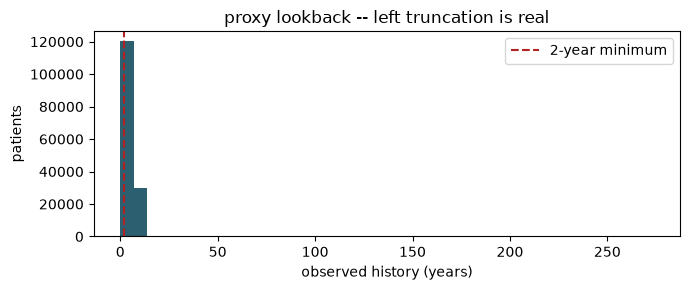


5899 patients (3.9%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [4]:
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [5]:
eo.resolve(concept, ['panic'], vocabularies=['SNOMED'])

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
2582,443698,Abnormal anal Papanicolaou smear,SNOMED,439855007,Condition
4312,40480043,Abnormal cervical Papanicolaou smear with huma...,SNOMED,441667007,Condition
23196,438559,Abnormal vaginal Papanicolaou smear,SNOMED,439856008,Condition
19359,4189538,Agoraphobia without history of panic disorder,SNOMED,61569007,Condition
1184,381584,Atrophic flaccid tympanic membrane,SNOMED,38645004,Condition
3496,374050,Atrophic nonflaccid tympanic membrane,SNOMED,72052003,Condition
23467,438167,Attic perforation of tympanic membrane,SNOMED,194315002,Condition
3436,443709,Atypical squamous cells of undetermined signif...,SNOMED,441086003,Condition
19317,434170,Atypical squamous cells of undetermined signif...,SNOMED,441087007,Condition
20294,441691,Atypical squamous cells of undetermined signif...,SNOMED,441099000,Condition


In [6]:
# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
bz = codesets['benzodiazepine']
print("benzodiazepine concepts, direct:      ", len(bz))
print("benzodiazepine concepts, + descendants:", len(eo.expand_descendants(bz)))

# And roll an unspecified diagnosis UP to its parents -- directly useful for the
# unspecified chest pain codes (R07.8, R07.89) this whole cohort is built from.
cp = codesets['chest_pain']
print("chest pain parents, 1 level up:  ", len(eo.roll_up(cp, levels=1)))

benzodiazepine concepts, direct:       65
benzodiazepine concepts, + descendants: 65
chest pain parents, 1 level up:   4


In [7]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
pharmacy                  7328452
office_visit              5383597
therapeutic_procedure_    1029791
radiologic_examination     877483
venipuncture_for_blood     749103
essential_hypertension     716115
somatic_dysfunction_of     713882
ekg                        709305
infectious_agent_detec     604962
anxiety                    584950
chiropractic_manipulat     561811
complete_blood_count_w     524343
comprehensive_metaboli     521101
manual_therapy_techniq     505288
chest_pain                 475433

tagged into a codeset: 7.2%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

## 3 · The bag of codes, and the exact failure

In [8]:
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :10]

(150368, 10823)


tag,0_05_ml_aflibercept_ay,0_07_ml_aflibercept_11,0_2_ml_glucagon_5_mg_m,0_2_ml_methotrexate_50,0_2_ml_sars_cov_2_covi,0_3_ml_bremelanotide_5,0_3_ml_enoxaparin_sodi,0_3_ml_methotrexate_50,0_3_ml_sars_cov_2_covi,0_4_ml_adalimumab_100_
person_id,,,,,,,,,,
22,0,0,0,0,0,0,0,0,0,0
50,0,0,0,0,0,0,0,0,0,0
67,0,0,0,0,0,0,0,0,1,0
68,0,0,0,0,0,0,0,0,1,0
321,0,0,0,0,0,0,0,0,0,0


Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `chest_pain` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

10823 codes, prevalence range 0.001% - 100.000%


,prevalence
tag,
chest_pain,100.0%
office_visit,86.6%
ekg,83.6%
radiologic_examination,77.3%
venipuncture_for_blood,71.9%
comprehensive_metaboli,67.9%
complete_blood_count_w,67.7%
lipid_panel_this_panel,63.7%
general_examination_of,57.9%


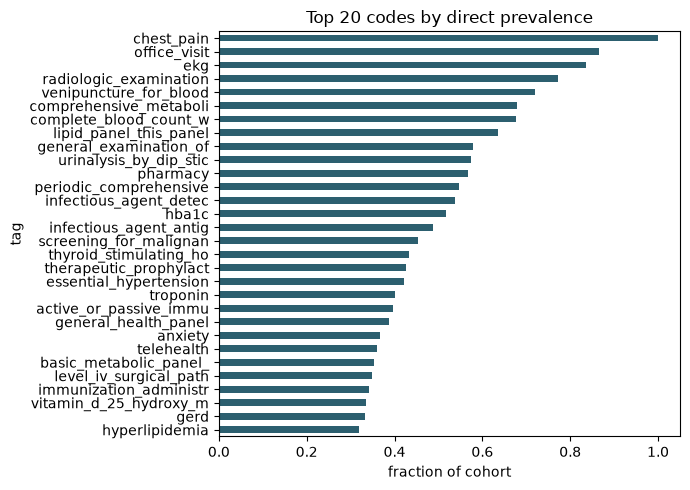

In [9]:
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(30).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 20 codes by direct prevalence')
plt.tight_layout(); plt.show()

In [10]:
# Two dx_9487 patients with a near-IDENTICAL bag of codes and opposite triage answers.
weak = eo.chest_pain_labels(events)                 # rule-based probe labels: psych vs cardiac
lab  = weak.set_index('person_id').chest_pain_label

both = [p for p in X.index
        if X.loc[p].get('chest_pain', 0) == 1
        and X.loc[p].get('ekg', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'psych'),   None)
b = next((p for p in both if lab[p] == 'cardiac'), None)
assert a and b, ("No matching-bag pair found in this sample. Widen the `both` filter, "
                 "or inspect `both` to see which side is missing.")

print("bag-of-codes view -- indistinguishable on chest_pain + ekg alone:")
display(X.loc[[a, b], ['chest_pain', 'ekg']])

print("\nactual timelines -- obviously different:")
FOCUS = ['chest_pain', 'ekg', 'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'troponin', 'stress_test', 'coronary_angio', 'cad']
for pid in (a, b):
    s = events[(events.person_id == pid) & events.tag.isin(FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'tag']].drop_duplicates('tag').to_string(index=False))

chest_pain patients: 150368   labelled: 69408   both-evidence (dropped): 36769   no-evidence (dropped): 44191
bag-of-codes view -- indistinguishable on chest_pain + ekg alone:


tag,chest_pain,ekg
person_id,,
50,1,1
389,1,1



actual timelines -- obviously different:

  person_id 50  (psych)
event_date        tag
2019-11-11        ekg
2021-11-30 chest_pain
2024-10-23    anxiety

  person_id 389  (cardiac)
event_date        tag
2023-06-29 chest_pain
2025-09-30        ekg
2025-09-30   troponin


**That is the motivation for the whole week.** Near-identical features, opposite triage
answer. The information lives in the order and the surrounding evidence, and a flat bag of
codes throws both away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

### On `chest_pain_labels()`

There is no adjudicated ground truth for "was this actually cardiac." `chest_pain_labels()`
builds probe labels from **corroborating co-evidence only** — anxiety/panic diagnoses,
SSRIs, or benzodiazepines on the `psych` side; troponin, stress tests, coronary
angiography, or a CAD diagnosis on the `cardiac` side. Patients with both kinds of
evidence, or neither, are dropped, and the counts are printed so you can see how many.

**The time order is deliberately not used here.** If you labelled by "anxiety dx before
chest pain code" and then tested whether the order predicts the label, you'd get perfect
accuracy by construction and learn nothing. Days 3-4 test order directly — the label has to
stay independent of it, or the test is circular.

In [11]:
from sklearn.metrics import pairwise_distances

# chest_pain is the cohort anchor -- ~100% prevalence here, so it's a near-
# constant column that carries no discriminative signal and would just eat a
# component. Drop it before any distance/SVD/NMF fit; X itself (with the
# column) stays untouched for the two-patient demo above and Table 1 below.
X_nmf = X.drop(columns=['chest_pain'])
Xv  = X_nmf.values.astype(float)
sub = Xv[:400]
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

pos = list(X.index).index(a)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(Xv[pos:pos+1], Xv, metric=m)[0]
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

cosine     mean=0.831  sd=0.068


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    mean=0.916  sd=0.041

cosine     neighbours of 50: ['?', 'cardiac', '?', 'cardiac', 'psych']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    neighbours of 50: ['cardiac', '?', '?', 'psych', 'cardiac']


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

## 5 · The curse of dimensionality

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

In [12]:
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

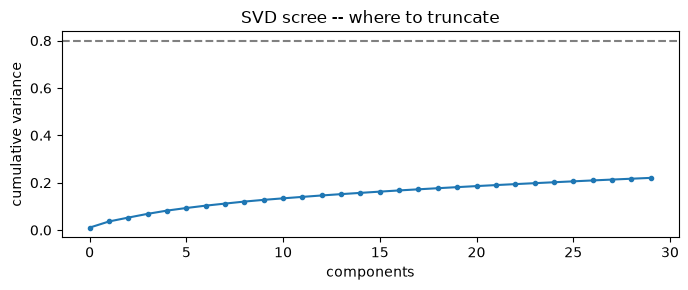

In [13]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

Xn  = normalize(Xv)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(30, Xv.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

In [14]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
# for k in [3, 5, 8, 12]:
for k in [5,12]:
    nmf = NMF(n_components=k, init='nndsvd', random_state=0, max_iter=800).fit(Xv)
    H   = pd.DataFrame(nmf.components_, columns=X_nmf.columns)
    print (f"\nNMF with {k} components:")
    for k in range(k):
        print(f"component {k}: {H.iloc[k].sort_values(ascending=False).head(5).index.tolist()}")


NMF with 5 components:
component 0: ['lipid_panel_this_panel', 'general_examination_of', 'office_visit', 'venipuncture_for_blood', 'ekg']
component 1: ['pharmacy', 'amoxicillin_875_mg_cla', '21_methylprednisolone_', '6_azithromycin_250_mg_', 'prednisone_20_mg_oral_']
component 2: ['troponin', 'therapeutic_prophylact', 'triacylglycerol_lipase', 'basic_metabolic_panel_', 'complete_blood_count_w']
component 3: ['therapeutic_procedure_', 'physical_therapy_evalu', 'manual_therapy_techniq', 'magnetic_resonance_eg_', 'application_of_a_modal']
component 4: ['gynecologic_examinatio', 'cytopathology_cervical', 'vitamin_d_25_hydroxy_m', 'infectious_agent_detec', 'mammogram']

NMF with 12 components:
component 0: ['troponin', 'complete_blood_count_w', 'comprehensive_metaboli', 'radiologic_examination', 'ekg']
component 1: ['pharmacy', '21_methylprednisolone_', 'amoxicillin_875_mg_cla', '6_azithromycin_250_mg_', 'prednisone_20_mg_oral_']
component 2: ['mammogram', 'screening_digital_brea', 'gyneco

Read those out loud — several are recognisable clinical bundles. **That is already a crude
motif catalog**, from a three-line factorisation, no deep learning involved. Keep it in your
pocket for the conversation about effort versus value.

## 7 · t-SNE, and how not to over-read it

In [15]:
# from sklearn.manifold import TSNE

# colour = (truth.set_index('person_id').archetype.reindex(X.index)
#           if truth is not None
#           else lab.reindex(X.index).fillna('unlabelled'))

# E = TSNE(n_components=2, init='pca', perplexity=30,
#          random_state=0).fit_transform(Z[:, :min(24, Z.shape[1])])

# fig, ax = plt.subplots(figsize=(7.5, 6))
# for name, g in pd.DataFrame({'x': E[:,0], 'y': E[:,1],
#                              'c': colour.values}).groupby('c', dropna=False):
#     ax.scatter(g.x, g.y, s=7, alpha=.6, label=str(name))
# ax.legend(fontsize=7, markerscale=2); ax.set_xticks([]); ax.set_yticks([])
# ax.set_title('t-SNE of bag-of-codes' +
#              (' -- coloured by planted truth (demo)' if truth is not None
#               else ' -- coloured by psych/cardiac label'))
# plt.tight_layout(); plt.show()

On the demo extract, look at where **DM_STABLE** and **DM_PROGRESSIVE** land. They overlap
heavily, because their code *sets* are nearly identical — the only difference is that one
adds GLP-1 and insulin *later*. Day 3 separates them cleanly.

### Three things never to claim from a t-SNE or UMAP plot

1. Cluster **sizes** are meaningful. They are not.
2. **Distances between** clusters are meaningful. They are not.
3. Apparent **density** is meaningful. It is a function of perplexity.

Never cluster on the 2-D output. Cluster in SVD space; use the projection only to look.

## Exercises

1. Re-run `load_events(domains=['Condition','Drug'])`. How much does dropping measurements
   and visits change the picture? (On real data this is also the difference between a
   3-minute and a 30-minute load.)
2. Widen a codeset regex on purpose — add `'.*statin'` to the statin set — and see what
   `resolve()` pulls in. This is how bad codesets happen.
3. Rebuild `X` with counts instead of binary. Does cosine still behave?
4. Restrict to `lookback_days >= 730` and repeat. Which apparent structure disappears?

## Carry forward

`X`, `Z`, and the weak probe labels. Day 2 clusters `Z` and profiles back through `X`.

## Table 1 · Cohort description

Standard epidemiological Table 1 for the dx_9487 cohort: demographics, lookback, comorbidity
prevalence, and — since we already fit one — each patient's dominant NMF component, stratified
by the `psych`/`cardiac` probe label from `chest_pain_labels()`. `Overall` is every patient
with a `chest_pain` code, including the ambiguous/no-evidence majority that the label drops;
`psych`/`cardiac` are the labelled subset only. Read the NMF rows as a sanity check: if the
component distribution barely differs between `psych` and `cardiac`, that is the same
bag-of-codes-can't-separate-them finding as the rest of Day 1, restated as a table.

In [16]:
cp_ids = set(events.loc[events.tag == 'chest_pain', 'person_id']) & set(X.index)
groups = {'Overall': cp_ids,
          'non-cardiac':   set(lab[lab != 'non-cardiac'].index)   & cp_ids,
          'cardiac': set(lab[lab == 'cardiac'].index) & cp_ids}
for name, ids in groups.items():
    print(f"{name}: {len(ids)} patients")

# age at first chest_pain, from person.birth_date
cp_index = eo.index_dates(events, 'chest_pain').set_index('person_id')['index_date']
birth    = person.set_index('person_id')['birth_date']
age_yrs  = (cp_index - birth.reindex(cp_index.index)).dt.days / 365.25

gender  = person.set_index('person_id')['gender'].astype(str).str.upper()
win_idx = win.set_index('person_id')['lookback_days']

CODE_ROWS = ['anxiety', 'panic_attack', 'ssri', 'benzodiazepine', 'gerd',
             'costochondritis', 'ekg', 'troponin', 'stress_test',
             'coronary_angio', 'cad']
has = {t: set(events.loc[events.tag == t, 'person_id']) for t in CODE_ROWS}

# dominant NMF component per patient, from the NMF already fit above (nmf, Xv, X)
W = nmf.transform(Xv)
dom_component = pd.Series(W.argmax(axis=1), index=X.index)

def describe(ids):
    n = len(ids)
    if n == 0:
        return {'N (%)': '0 (0.0)'}
    row = {'N (%)': f"{n} ({n / len(cp_ids) * 100:.1f})"}
    a_yrs = age_yrs.reindex(ids)
    row['Age, mean (SD)'] = f"{a_yrs.mean():.1f} ({a_yrs.std():.1f})"
    row['Female, %'] = f"{(gender.reindex(ids) == 'FEMALE').mean() * 100:.1f}"
    lb = win_idx.reindex(ids)
    row['Lookback days, median (IQR)'] = (
        f"{lb.median():.0f} ({lb.quantile(.25):.0f}-{lb.quantile(.75):.0f})")
    for t in CODE_ROWS:
        row[f'{t}, %'] = f"{len(has[t] & ids) / n * 100:.1f}"
    for k in range(8):
        row[f'NMF component {k}, %'] = f"{(dom_component.reindex(ids) == k).mean() * 100:.1f}"
    return row

table1 = pd.DataFrame({name: describe(ids) for name, ids in groups.items()})
display(table1)

Overall: 150368 patients
non-cardiac: 69408 patients
cardiac: 36764 patients


,Overall,non-cardiac,cardiac
N (%),150368 (100.0),69408 (46.2),36764 (24.4)
"Age, mean (SD)",44.8 (10.2),45.1 (10.2),46.9 (9.8)
"Female, %",43.3,43.0,34.2
"Lookback days, median (IQR)",2291 (1873-2478),2303 (1896-2480),2204 (1752-2437)
"anxiety, %",36.6,35.4,0.0
"panic_attack, %",4.7,4.0,0.0
"ssri, %",15.1,17.7,0.0
"benzodiazepine, %",15.0,15.4,0.0
"gerd, %",33.4,32.9,31.8
"costochondritis, %",3.2,3.1,3.0
